# Présentation PINN

Sources :

- Maziar Raissi, Paris Perdikaris, George Em Karniadakis. *Physics Informed Deep Learning (Part I): Data-driven Solutions of Nonlinear Partial Differential Equations*. [arXiv 1711.10561](https://arxiv.org/abs/1711.10561) 
- Maziar Raissi, Paris Perdikaris, George Em Karniadakis. *Physics Informed Deep Learning (Part II): Data-driven Discovery of Nonlinear Partial Differential Equations*. [arXiv 1711.10566](https://arxiv.org/abs/1711.10566) 
- Maziar Raissi, Paris Perdikaris, George Em Karniadakis. *Physics-informed neural networks: A deep learning framework for solving forward and inverse problems involving nonlinear partial differential equations*. J. Comp. Phys. 378 pp. 686-707 [DOI: 10.1016/j.jcp.2018.10.045](https://www.sciencedirect.com/science/article/pii/S0021999118307125) 

This notebook is partially based on another implementation of the PINN approach published on [GitHub by pierremtb](https://github.com/pierremtb/PINNs-TF2.0) as well as the original code, see [Maziar Raissi on GitHub](https://github.com/maziarraissi/PINNs).

<a href="https://colab.research.google.com/github/janblechschmidt/PDEsByNNs/blob/main/PINN_Solver.ipynb" target="_parent">
    <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/>
</a>

## Introduction

We describe the PINN approach for approximating the solution $u:[0,T] \times \mathcal{D} \to \mathbb{R}$ of an evolution equation

$$
\begin{align}
    \partial_t u (t,x) + \mathcal{N}[u](t,x) &= 0, && (t,x) \in (0,T] \times \mathcal{D},\\
    u(0,x) &= u_0(x) \quad && x \in \mathcal{D},
\end{align}
$$

where $\mathcal{N}$ is a nonlinear differential operator acting on $u$, 
$\mathcal{D} \subset \mathbb{R}^d$ a bounded domain,
$T$ denotes the final time and
$u_0: \mathcal{D} \to \mathbb{R}$ the prescribed initial data.
Although the methodology allows for different types of boundary conditions, we restrict our discussion to the inhomogeneous Dirichlet case and prescribe

$$
\begin{align}
        \hspace{7em} u(t,x) &= u_b(t,x)  && \quad (t,x) \in (0,T] \times \partial \mathcal{D},
\end{align}
$$

where $\partial \mathcal{D}$ denotes the boundary of the domain $\mathcal{D}$ and $u_b: (0,T] \times \partial \mathcal{D} \to \mathbb{R}$ the given boundary data.

## Methodology

The method constructs a neural network approximation

$$
u_\theta(t,x) \approx u(t,x)
$$

of the solution of nonlinear PDE, where $u_\theta :[0,T] \times \mathcal{D} \to \mathbb{R}$ denotes a function realized by a neural network with parameters $\theta$.

The continuous time approach for the parabolic PDE as described in ([Raissi et al., 2017 (Part I)](https://arxiv.org/abs/1711.10561)) is based on the (strong) residual of a given neural network approximation $u_\theta \colon [0,T] \times \mathcal{D} \to \mathbb{R} $ of the solution $u$, i.e.,

$$
\begin{align}
    r_\theta (t,x) := \partial_t u_\theta (t,x) + \mathcal{N}[u_\theta] (t,x).
\end{align}
$$

To incorporate this PDE residual $r_\theta$ into a loss function to be minimized, PINNs require a further differentiation to evaluate the differential operators $\partial_t u_\theta$ and $\mathcal{N}[u_\theta]$.
Thus the PINN term $r_\theta$ shares the same parameters as the original network $u_\theta(t,x)$, but respects the underlying "physics" of the nonlinear PDE.
Both types of derivatives can be easily determined through automatic differentiation with current state-of-the-art machine learning libraries, e.g., TensorFlow or PyTorch.

The PINN approach for the solution of the initial and boundary value problem now proceeds by minimization of the loss functional

$$
\begin{align}
    \phi_\theta(X) := \phi_\theta^r(X^r) + \phi_\theta^0(X^0) + \phi_\theta^b(X^b),
\end{align}
$$

where $X$ denotes the collection of training data and the loss function $\phi_\theta$ contains the following terms:

  - the mean squared residual
$$
  \begin{align*}
   \phi_\theta^r(X^r) := \frac{1}{N_r}\sum_{i=1}^{N_r} \left|r_\theta\left(t_i^r, x_i^r\right)\right|^2
\end{align*}
$$
in a number of collocation points $X^r:=\{(t_i^r, x_i^r)\}_{i=1}^{N_r} \subset (0,T] \times \mathcal{D}$, where $r_\theta$ is the physics-informed neural network,
  - the mean squared misfit with respect to the initial and boundary conditions
$$
    \begin{align*}
   \phi_\theta^0(X^0) 
   := 
   \frac{1}{N_0}
   \sum_{i=1}^{N_0} \left|u_\theta\left(t_i^0, x_i^0\right) - u_0\left(x_i^0\right)\right|^2
   \quad \text{ and } \quad
   \phi_\theta^b(X^b) 
   := 
   \frac{1}{N_b}
   \sum_{i=1}^{N_b} \left|u_\theta\left(t_i^b, x_i^b\right) - u_b\left(t_i^b, x_i^b\right)\right|^2
    \end{align*}
$$
in a number of points $X^0:=\{(t^0_i,x^0_i)\}_{i=1}^{N_0} \subset \{0\} \times \mathcal{D}$ and $X^b:=\{(t^b_i,x^b_i)\}_{i=1}^{N_b} \subset (0,T] \times \partial \mathcal{D}$, where $u_\theta$ is the neural network approximation of the solution $u\colon[0,T] \times \mathcal{D} \to \mathbb{R}$.

Note that the training data $X$ consists entirely of time-space coordinates.


# Résolution de l'équation de Burgers 

To illustrate the PINN approach we consider the one-dimensional Burgers equation on the spatial domain $\mathcal{D} = [-1,1]$

$$
\begin{aligned}
    \partial_t u + u \, \partial_x u - (0.01/\pi) \, \partial_{xx} u &= 0, \quad &&\quad (t,x) \in (0,1] \times (-1,1),\\
   u(0,x) &= - \sin(\pi \, x),                 \quad &&\quad x \in [-1,1],\\
   u(t,-1) = u(t,1) &= 0,                      \quad &&\quad t \in (0,1].
\end{aligned}
$$

This PDE arises in various disciplines such as traffic flow, fluid mechanics and gas dynamics, and can be derived from the Navier-Stokes equations, see 
([Basdevant et al., 1986](https://www.researchgate.net/publication/222935980_Spectral_and_finite_difference_solutions_of_Burgers_equation)).

## Import

In [3]:
import tensorflow as tf
import numpy as np
import copy as cp
import scipy.sparse.linalg as linalg
import matplotlib.pyplot as plt
from time import time
import scipy.optimize

gpus = tf.config.experimental.list_physical_devices('GPU')
for gpu in gpus:
  tf.config.experimental.set_memory_growth(gpu, True)

## Paramètres du problème

In [4]:
# Set data type
DTYPE='float32'
tf.keras.backend.set_floatx(DTYPE)

# Set constants
pi = tf.constant(np.pi, dtype=DTYPE)
viscosity = 0.01/pi

# Set boundary
tmin = 0.
tmax = 1.
xmin = -1.
xmax = 1.

# Lower bounds
lb = tf.constant([tmin, xmin], dtype=DTYPE)
# Upper bounds
ub = tf.constant([tmax, xmax], dtype=DTYPE)

# Define initial condition
def fun_u_0(x):
    return -tf.sin(pi * x)

# Define boundary condition
def fun_u_b(t, x):
    n = x.shape[0]
    return tf.zeros((n,1), dtype=DTYPE)

## Générer les données d'entrainements

In [9]:
def gen_train_data(N_0=100, N_b=100, N_r=10_000):

    # Set random seed for reproducible results
    tf.random.set_seed(0)

    # Draw uniform sample points for initial boundary data
    t_0 = tf.ones((N_0,1), dtype=DTYPE)*lb[0]
    x_0 = tf.random.uniform((N_0,1), lb[1], ub[1], dtype=DTYPE)
    X_0 = tf.concat([t_0, x_0], axis=1)

    # Evaluate intitial condition at x_0
    u_0 = fun_u_0(x_0)

    # Boundary data
    t_b = tf.random.uniform((N_b,1), lb[0], ub[0], dtype=DTYPE)
    x_b = lb[1] + (ub[1] - lb[1]) * tf.keras.backend.random_bernoulli((N_b,1), 0.5, dtype=DTYPE)
    X_b = tf.concat([t_b, x_b], axis=1)

    # Evaluate boundary condition at (t_b,x_b)
    u_b = fun_u_b(t_b, x_b)

    # Draw uniformly sampled collocation points
    t_r = tf.random.uniform((N_r,1), lb[0], ub[0], dtype=DTYPE)
    x_r = tf.random.uniform((N_r,1), lb[1], ub[1], dtype=DTYPE)
    X_r = tf.concat([t_r, x_r], axis=1)

    # Collect boundary and inital data in lists
    X_data = [X_0, X_b]
    u_data = [u_0, u_b]

    return X_r, X_data, u_data

def plot_train_data(X_r, X_data, u_data):

    X_0 = X_data[0]
    t_0 = X_0[:,0]
    x_0 = X_0[:,1]

    X_b = X_data[1]
    t_b = X_b[:,0]
    x_b = X_b[:,1]

    t_r = X_r[:,0]
    x_r = X_r[:,1]

    u_0 = u_data[0]
    u_b = u_data[1]

    fig = plt.figure(figsize=(9,6))
    plt.scatter(t_0, x_0, c=u_0, marker='X', vmin=-1, vmax=1)
    plt.colorbar()
    plt.scatter(t_b, x_b, c=u_b, marker='X', vmin=-1, vmax=1)
    plt.scatter(t_r, x_r, c='r', marker='.', alpha=0.1)
    plt.xlabel('$t$')
    plt.ylabel('$x$')

    plt.title('Positions of collocation points and boundary data');
    #plt.savefig('Xdata_Burgers.pdf', bbox_inches='tight', dpi=300)

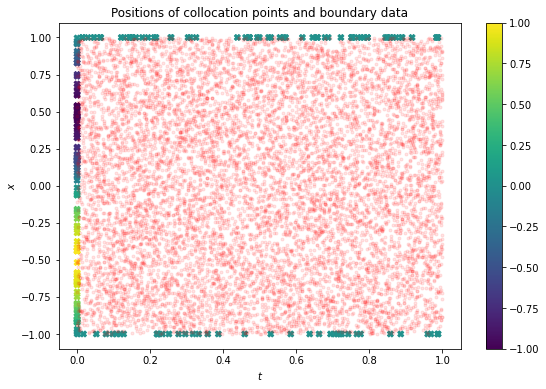

In [10]:
X_r, X_data, u_data = gen_train_data(100,100,10_000)
plot_train_data(X_r, X_data, u_data)

## Le modèle avec tensorflow

In [11]:
class PhysicsInformedNN(tf.keras.Model):
    """ Set basic architecture of the PINN model."""

    def __init__(self, lb, ub, 
            output_dim=1,
            num_hidden_layers=8, 
            num_neurons_per_layer=20,
            activation='tanh',
            kernel_initializer='glorot_normal',
            **kwargs):
        super().__init__(**kwargs)

        self.num_hidden_layers = num_hidden_layers
        self.output_dim = output_dim
        self.lb = lb
        self.ub = ub
        
        # Define NN architecture
        self.scale = tf.keras.layers.Lambda(
            lambda x: 2.0*(x - lb)/(ub - lb) - 1.0)
        self.hidden = [tf.keras.layers.Dense(num_neurons_per_layer,
                             activation=tf.keras.activations.get(activation),
                             kernel_initializer=kernel_initializer)
                           for _ in range(self.num_hidden_layers)]
        self.out = tf.keras.layers.Dense(output_dim)
        
    def call(self, X):
        """Forward-pass through neural network."""
        Z = self.scale(X)
        for i in range(self.num_hidden_layers):
            Z = self.hidden[i](Z)
        return self.out(Z)

In [12]:
class PINNSolver():
    def __init__(self, model, X_r):
        self.model = model
        
        # Store collocation points
        self.t = X_r[:,0:1]
        self.x = X_r[:,1:2]
        
        # Initialize history of losses and global iteration counter
        self.hist = []
        self.iter = 0
    
    def get_r(self):
        
        with tf.GradientTape(persistent=True) as tape:
            # Watch variables representing t and x during this GradientTape
            tape.watch(self.t)
            tape.watch(self.x)
            
            # Compute current values u(t,x)
            u = self.model(tf.stack([self.t[:,0], self.x[:,0]], axis=1))
            
            u_x = tape.gradient(u, self.x)
            
        u_t = tape.gradient(u, self.t)
        u_xx = tape.gradient(u_x, self.x)
        
        del tape
        
        return self.fun_r(self.t, self.x, u, u_t, u_x, u_xx)
    
    def loss_fn(self, X, u):
        
        # Compute phi_r
        r = self.get_r()
        phi_r = tf.reduce_mean(tf.square(r))
        
        # Initialize loss
        loss = phi_r

        # Add phi_0 and phi_b to the loss
        for i in range(len(X)):
            u_pred = self.model(X[i])
            loss += tf.reduce_mean(tf.square(u[i] - u_pred))
        
        return loss
    
    def get_grad(self, X, u):
        with tf.GradientTape(persistent=True) as tape:
            # This tape is for derivatives with
            # respect to trainable variables
            tape.watch(self.model.trainable_variables)
            loss = self.loss_fn(X, u)
            
        g = tape.gradient(loss, self.model.trainable_variables)
        del tape
        
        return loss, g
    
    def fun_r(self, t, x, u, u_t, u_x, u_xx):
        """Residual of the PDE"""
        return u_t + u * u_x - viscosity * u_xx
    
    def solve_with_TFoptimizer(self, optimizer, X, u, N=1001):
        """This method performs a gradient descent type optimization."""
        
        @tf.function
        def train_step():
            loss, grad_theta = self.get_grad(X, u)
            
            # Perform gradient descent step
            optimizer.apply_gradients(zip(grad_theta, self.model.trainable_variables))
            return loss
        
        for i in range(N):
            
            loss = train_step()
            
            self.current_loss = loss.numpy()
            self.callback()

    def solve_with_ScipyOptimizer(self, X, u, method='L-BFGS-B'):
        
        def get_weight_tensor():
            """Function to return current variables of the model
            as 1d tensor as well as corresponding shapes as lists."""
            
            weight_list = []
            shape_list = []
            
            # Loop over all variables, i.e. weight matrices, bias vectors and unknown parameters
            for v in self.model.variables:
                shape_list.append(v.shape)
                weight_list.extend(v.numpy().flatten())
                
            weight_list = tf.convert_to_tensor(weight_list)
            return weight_list, shape_list

        x0, shape_list = get_weight_tensor()
        
        def set_weight_tensor(weight_list):
            """Function which sets list of weights
            to variables in the model."""
            idx = 0
            for v in self.model.variables:
                vs = v.shape
                
                # Weight matrices
                if len(vs) == 2:  
                    sw = vs[0]*vs[1]
                    new_val = tf.reshape(weight_list[idx:idx+sw],(vs[0],vs[1]))
                    idx += sw
                
                # Bias vectors
                elif len(vs) == 1:
                    new_val = weight_list[idx:idx+vs[0]]
                    idx += vs[0]
                    
                # Variables (in case of parameter identification setting)
                elif len(vs) == 0:
                    new_val = weight_list[idx]
                    idx += 1
                    
                # Assign variables (Casting necessary since scipy requires float64 type)
                v.assign(tf.cast(new_val, DTYPE))
        
        def get_loss_and_grad(w):
            """Function that provides current loss and gradient
            w.r.t the trainable variables as vector. This is mandatory
            for the LBFGS minimizer from scipy."""
            
            # Update weights in model
            set_weight_tensor(w)
            # Determine value of \phi and gradient w.r.t. \theta at w
            loss, grad = self.get_grad(X, u)
            
            # Store current loss for callback function            
            loss = loss.numpy().astype(np.float64)
            self.current_loss = loss            
            
            # Flatten gradient
            grad_flat = []
            for g in grad:
                grad_flat.extend(g.numpy().flatten())
            
            # Gradient list to array
            grad_flat = np.array(grad_flat,dtype=np.float64)
            
            # Return value and gradient of \phi as tuple
            return loss, grad_flat
        
        
        return scipy.optimize.minimize(fun=get_loss_and_grad,
                                       x0=x0,
                                       jac=True,
                                       method=method,
                                       callback=self.callback,
                                       options={'maxiter': 2000,
                                                'maxfun': 50000,
                                                'maxcor': 50,
                                                'maxls': 50,
                                                'ftol': 1.0*np.finfo(float).eps})
        
    def callback(self, xr=None):
        if self.iter % 100 == 0:
            print('Iteration {:05d}: loss = {:10.8e}'.format(self.iter,self.current_loss))
        self.hist.append(self.current_loss)
        self.iter+=1
                
    def plot_loss_history(self, ax=None):

        if not ax:
            fig = plt.figure(figsize=(7,5))
            ax = fig.add_subplot(111)

        ax.semilogy(range(len(self.hist)), self.hist,'k-')
        ax.set_xlabel('$Iteration$')
        ax.set_ylabel('Loss')

        return ax

    def plot_solution(self):

      fig, axs = plt.subplots(1, 3, figsize=(20,5))

      N=600
      xspace = np.linspace(lb[1], ub[1], N + 1)

      all_times=[0.,0.5,1.0]
      for i_t, end_time in enumerate(all_times):
        
        T, X = np.meshgrid(end_time, xspace)
        Xgrid = np.vstack([T.flatten(),X.flatten()]).T
        upred = self.model(tf.cast(Xgrid,DTYPE))

        axs[i_t].plot(xspace,upred, 'b-', label="PINN prediction")
        axs[i_t].set_title("t=" + str(end_time), fontsize = 10)
        axs[i_t].set_xlabel('$x$')
        axs[i_t].set_ylabel('$u(t,x)$')    
        axs[i_t].axis('square')
        axs[i_t].set_xlim([-1.1,1.1])
        axs[i_t].set_ylim([-1.1,1.1]);

      handles, labels = axs[-1].get_legend_handles_labels()
      fig.legend(handles, labels, loc='lower center', ncol=4);

      plt.suptitle("PINN prediction at different time after {} training step".format(self.iter));

### Exemple utilisation 

In [21]:
# Initialize PINN model
model = PhysicsInformedNN(lb, ub)
model.build(input_shape=(None,2))

# Initilize PINN solver
solver = PINNSolver(model, X_r)

model.summary()

Model: "physics_informed_nn_1"
_________________________________________________________________
Layer (type)                 Output Shape              Param #   
lambda_1 (Lambda)            multiple                  0         
_________________________________________________________________
dense_9 (Dense)              multiple                  60        
_________________________________________________________________
dense_10 (Dense)             multiple                  420       
_________________________________________________________________
dense_11 (Dense)             multiple                  420       
_________________________________________________________________
dense_12 (Dense)             multiple                  420       
_________________________________________________________________
dense_13 (Dense)             multiple                  420       
_________________________________________________________________
dense_14 (Dense)             multiple        

visualisation du résultat avant l'entrainement

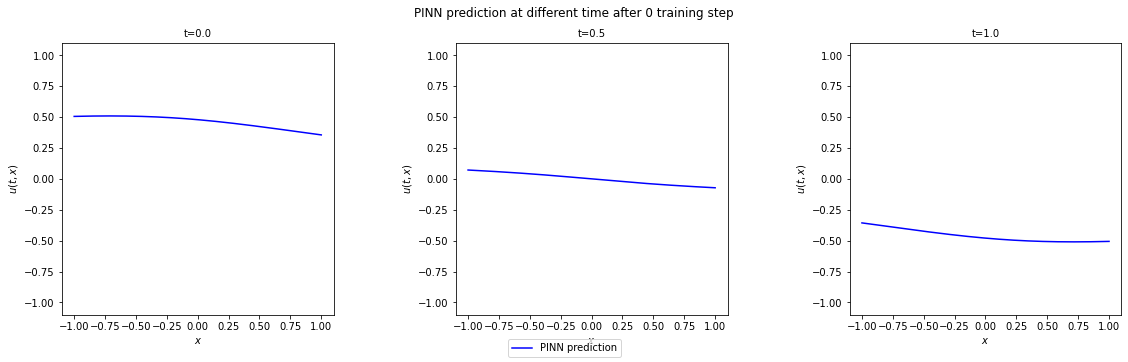

In [22]:
solver.plot_solution()

In [23]:
t0 = time()
try: 
  lr = tf.keras.optimizers.schedules.ExponentialDecay(
    1e-4,
    decay_steps=1000,
    decay_rate=0.9,
    staircase=True)
  optim = tf.keras.optimizers.Adam(learning_rate=lr)
  solver.solve_with_TFoptimizer(optim, X_data, u_data, N=4001)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 00000: loss = 1.83411098e+00
Iteration 00100: loss = 4.19460446e-01
Iteration 00200: loss = 3.89578581e-01
Iteration 00300: loss = 3.64546895e-01
Iteration 00400: loss = 3.36267740e-01
Iteration 00500: loss = 2.93616444e-01
Iteration 00600: loss = 2.40121946e-01
Iteration 00700: loss = 2.03472763e-01
Iteration 00800: loss = 1.87262341e-01
Iteration 00900: loss = 1.78580835e-01
Iteration 01000: loss = 1.71303868e-01
Iteration 01100: loss = 1.64931476e-01
Iteration 01200: loss = 1.58557624e-01
Iteration 01300: loss = 1.52202681e-01
Iteration 01400: loss = 1.45978048e-01
Iteration 01500: loss = 1.40042692e-01
Iteration 01600: loss = 1.34537593e-01
Iteration 01700: loss = 1.29561111e-01
Iteration 01800: loss = 1.25158221e-01
Iteration 01900: loss = 1.21290371e-01
Iteration 02000: loss = 1.17842935e-01
Iteration 02100: loss = 1.14987269e-01
Iteration 02200: loss = 1.12291232e-01
Iteration 02300: loss = 1.09731138e-01
Iteration 02400: loss = 1.07311063e-01
Iteration 02500: loss = 1

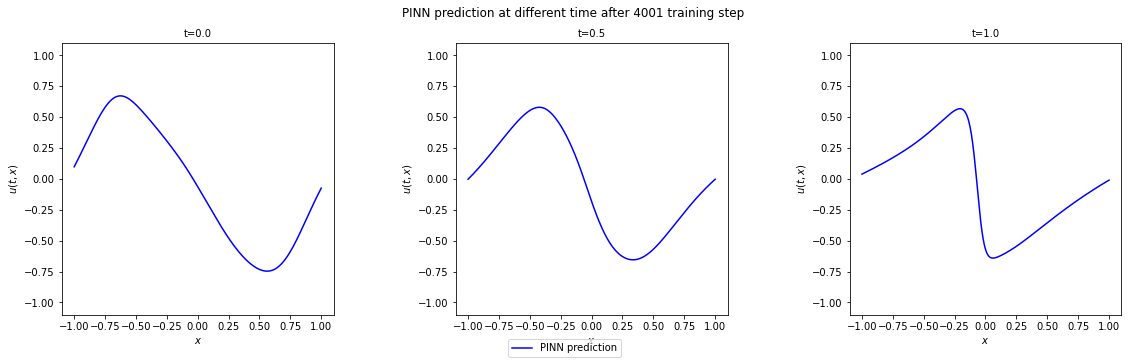

In [24]:
solver.plot_solution()

In [25]:
t0 = time()
try: 
  solver.solve_with_ScipyOptimizer(X_data, u_data)
except:
  pass

print('\nTraining time: {} seconds'.format(time()-t0))

Iteration 04100: loss = 3.23723182e-02
Iteration 04200: loss = 1.02258325e-02
Iteration 04300: loss = 5.15909586e-03
Iteration 04400: loss = 2.94575514e-03
Iteration 04500: loss = 1.67036429e-03
Iteration 04600: loss = 9.65925923e-04
Iteration 04700: loss = 5.95201680e-04
Iteration 04800: loss = 3.93959694e-04
Iteration 04900: loss = 2.82631372e-04
Iteration 05000: loss = 1.88537248e-04
Iteration 05100: loss = 1.47940169e-04
Iteration 05200: loss = 1.16191244e-04
Iteration 05300: loss = 9.20158054e-05
Iteration 05400: loss = 7.77527239e-05
Iteration 05500: loss = 6.42863524e-05
Iteration 05600: loss = 5.26328768e-05
Iteration 05700: loss = 4.31890185e-05
Iteration 05800: loss = 3.45465123e-05
Iteration 05900: loss = 2.89074742e-05
Iteration 06000: loss = 2.49671448e-05

Training time: 161.63911700248718 seconds


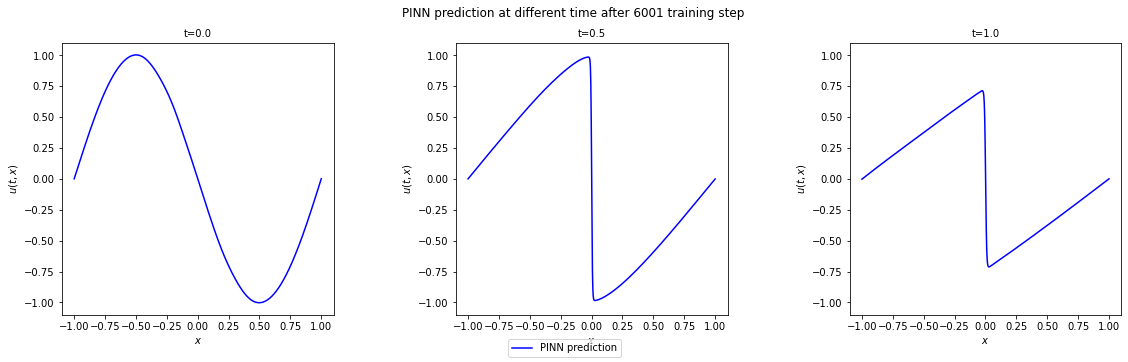

In [26]:
solver.plot_solution()

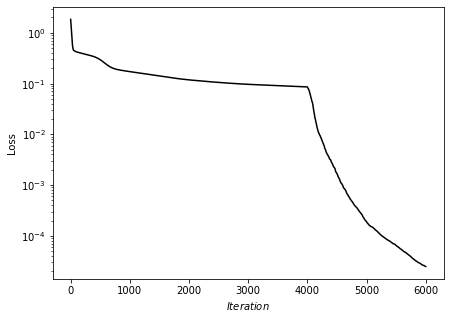

In [27]:
solver.plot_loss_history();

# Comparaison PINN vs volume finis

## Méthode des volumes finis 

In [28]:
# Classe résolvant Burgers avec des volumes finis 1D (cours P. Helluy)
class EDP:
    def __init__(self,Nx,viscosity, u_0):
      
        self.Nx=Nx  # nb mailles
        self.a=-1.0  # bord gauche du domaine
        self.b=1.0  # bord droit du domaine
        self.viscosity = viscosity
        self.dt=0.0
        self.u_0 = u_0       

        # Pour le maillage Nx mailles et 2 maillages fantome a gauche et droite pour les conditions limites
        self.h=(self.b-self.a)/self.Nx  # pas de maillage
        self.begin = 1  # numéro de la première maille non fantome
        self.end=  self.Nx+1  # numéro de la dernière maille non fantome  
        
        self.nodes=np.linspace(self.a-self.h,self.b+self.h,self.Nx+3) 
        #listes des noeuds: n+1 noeuds et 2 noeuds fantomes
        self.cells=np.linspace(self.a-0.5*self.h,self.b+0.5*self.h,self.Nx+2)
        #listes des centres de mailles: n centres et 2 centres fantomes
        self.rho= np.zeros(self.Nx+2) ## rho sur le maillage + mailles fantomes
    
    #fonction pour initialiser rho
    def init(self):
    
        for i in range(0,len(self.rho)):
            self.rho[i]=self.u_0(self.cells[i])
    
        # on conserve le rho initiale
        self.rho_0=cp.copy(self.rho)

    # flux volumes finis de Lax-Friedrichs
    def flux_hyp_burgers(self,rl,rr):
        center = 0.5*(0.5*rl*rl+0.5*rr*rr)
        vel = max(abs(rl),abs(rr))
        visco=0.5*vel*(rl-rr)
        return center+visco
        
    # flux volumes finis du terme de diffusion
    def flux_diff(self,rl,rr):
        grad = self.viscosity*(rr-rl)/self.h
        return grad
    
    # plot de rho_0 et de rho
    def plot(self):
        fig, axes = plt.subplots(1, 2, figsize=(12, 4))
        axes[0].plot(self.cells[self.begin:self.end],self.rho_0[self.begin:self.end],'r-')
        axes[1].plot(self.cells[self.begin:self.end],self.rho[self.begin:self.end],'b-')
        
    # condition limite dans les mailles fantomes selon le cas test. A expliquer
    def bc(self):
        self.rho[0]=0
        self.rho[-1]=0
    
    # le terme de diffusion est traité par un schéma implicite en temps
    # le terme de Burgers par un schema implicite
    # Ici on contruit le produit matrice vecteur entre la matrice implicite et un vecteur v
    def matvec_Laplacian(self,v):
        res=np.zeros(self.Nx)
        vl=0.0
        vr=0.0

        res[0]= v[0]-self.dt*self.viscosity/(self.h**2.0)*(vl-2.0*v[0]+v[1])
        for i in range(1,self.Nx-1):
            res[i]= v[i]-self.dt*self.viscosity/(self.h**2.0)*(v[i-1]-2.0*v[i]+v[i+1])
            
        res[-1]= v[-1]-self.dt*self.viscosity/(self.h**2.0)*(v[-2]-2.0*v[-1]+vr)
        return res
        
    # Résolution de l'équation en temps
    # A est un opérateur linéaire associée à la matrice implicite (le produit matrice vecteur)
    # on a pas besoin de construire la matrice pour résoudre un problème avec le gradient conjugé.
    # Il suffit juste de donner ce produit matrice vecteur
    def solve_loc(self,T,flux):
        sol=[]
        nt = 0
        time = 0.0
        rho_temp = np.zeros(self.Nx)
        self.A = linalg.LinearOperator((self.Nx,self.Nx), matvec=self.matvec_Laplacian)
        while time < T:
            # vitesse max de l'équation utile pour CFL
            vmax=max(abs(self.rho[self.begin:self.end]))
            self.dt= 0.5*self.h/vmax
            for i in range(0,self.Nx):
                # calcul des conditions limites dans la mailles fantomes
                self.bc()
                rhol = self.rho[self.begin+i-1]
                rhoc = self.rho[self.begin+i]
                rhor = self.rho[self.begin+i+1]
                # calcul des flux explicite
                fh=flux(rhoc,rhor)-flux(rhol,rhoc)
                # schéma en temps explicite
                rho_temp[i]=rhoc -self.dt/self.h*fh
        
            # schéma en temps implicite en résovlant Arho^{n+1}= Explicit
            self.rho[self.begin:self.end],info=linalg.cg(self.A,rho_temp,x0=None,tol=1e-06,maxiter=200)
            sol.append(cp.copy(self.rho[self.begin:self.end]))
            time=time+self.dt
            nt=nt+1
        return sol
    
    def solve(self,T):
        sol=self.solve_loc(T,self.flux_hyp_burgers)
        return sol

In [29]:
def u_0(x):
  return -np.sin(np.pi*x)

In [34]:
all_times = [0.25, 0.5, 1.0]
exact_solutions = []
N = 800

bg=EDP(N, viscosity.numpy() , u_0)
x = bg.cells[bg.begin:bg.end]


t0 = time()
try: 
    for i_t, end_time in enumerate(all_times):
      bg.init()
      sol=bg.solve(end_time)
      exact_solutions.append(sol[-1])
except:
  pass

print('\nComputing time: {} seconds'.format(time()-t0))



Computing time: 30.36611270904541 seconds


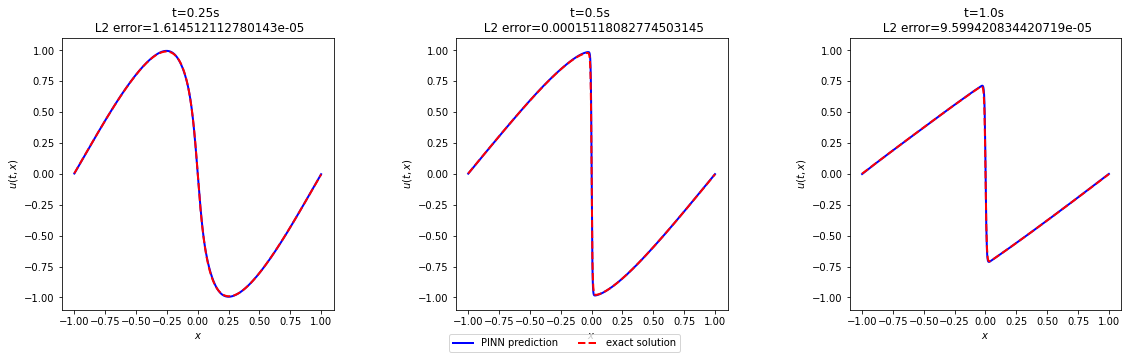

In [35]:
fig, ax = plt.subplots(1, 3, figsize=(20, 5))

for i_t, end_time in enumerate(all_times):

    exact_sol = exact_solutions[i_t]

    # solution en utilisant le PINN
    T, X = np.meshgrid(end_time, x)
    Xgrid = np.vstack([T.flatten(),X.flatten()]).T
    upred = model(tf.cast(Xgrid,DTYPE))
    upred = tf.reshape(upred, (1,N))[0].numpy()

    # affichage
    erreurL2 = (x[-1]-x[0])/N*np.sum((exact_sol-upred)**2)
    title = "t={}s \n L2 error={}".format(end_time, erreurL2)
    ax[i_t].set_title(title)

    ax[i_t].plot(x, upred, 'b-', linewidth = 2, label="PINN prediction")
    ax[i_t].plot(x, exact_sol, 'r--', linewidth = 2, label="exact solution")

    ax[i_t].set_xlabel('$x$')
    ax[i_t].set_ylabel('$u(t,x)$')    
    ax[i_t].axis('square')
    ax[i_t].set_xlim([-1.1,1.1])
    ax[i_t].set_ylim([-1.1,1.1]);

handles, labels = ax[-1].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4);

# Influence des paramètres du problème

In [45]:
def conv_study(N_0=100, N_b=100, N_r=10_000, num_hidden_layers=8, num_neurons_per_layer=20):

    X_r, X_data, u_data = gen_train_data(N_0, N_b, N_r)

    model = PhysicsInformedNN(lb, ub, num_hidden_layers=num_hidden_layers, num_neurons_per_layer=num_neurons_per_layer)
    model.build(input_shape=(None,2))

    solver = PINNSolver(model, X_r)

    t0 = time()
    try: 
      solver.solve_with_ScipyOptimizer(X_data, u_data)
    except:
      pass

    print('\nTraining time: {} seconds'.format(time()-t0))

    fig, ax = plt.subplots(1, 3, figsize=(20, 5))

    alltimes = [0.25, 0.5, 1.0]
    for i_t, end_time in enumerate(all_times):

        # solution exacte
        exact_sol = exact_solutions[i_t]

        # solution en utilisant le PINN
        T, X = np.meshgrid(end_time, x)
        Xgrid = np.vstack([T.flatten(),X.flatten()]).T
        upred = model(tf.cast(Xgrid,DTYPE))
        upred = tf.reshape(upred, (1,N))[0].numpy()

        # affichage
        erreurL2 = (x[-1]-x[0])/N*np.sum((exact_sol-upred)**2)
        title = "t={}s \n L2 error={}".format(end_time, erreurL2)
        ax[i_t].set_title(title)

        ax[i_t].plot(x, upred, 'b-', linewidth = 2, label="PINN prediction")
        ax[i_t].plot(x, exact_sol, 'r--', linewidth = 2, label="exact solution")

        ax[i_t].set_xlabel('$x$')
        ax[i_t].set_ylabel('$u(t,x)$')    
        ax[i_t].axis('square')
        ax[i_t].set_xlim([-1.1,1.1])
        ax[i_t].set_ylim([-1.1,1.1]);

    handles, labels = ax[-1].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=4);

    solver.plot_loss_history();

## Nombre de paramètres du modèle

Pour un nombre de points d'entrainement fixé.

Iteration 00000: loss = 8.49216521e-01
Iteration 00100: loss = 8.80138725e-02
Iteration 00200: loss = 2.72531044e-02
Iteration 00300: loss = 1.29708042e-02
Iteration 00400: loss = 6.36038696e-03
Iteration 00500: loss = 3.36367590e-03
Iteration 00600: loss = 2.15820665e-03
Iteration 00700: loss = 1.47107360e-03
Iteration 00800: loss = 9.70820431e-04
Iteration 00900: loss = 7.38786825e-04
Iteration 01000: loss = 6.07691181e-04
Iteration 01100: loss = 5.24635601e-04
Iteration 01200: loss = 4.42522374e-04
Iteration 01300: loss = 3.82248400e-04
Iteration 01400: loss = 3.37388279e-04
Iteration 01500: loss = 2.98131723e-04
Iteration 01600: loss = 2.81368790e-04
Iteration 01700: loss = 2.67488271e-04
Iteration 01800: loss = 2.46285956e-04
Iteration 01900: loss = 2.30252190e-04

Training time: 116.48242712020874 seconds


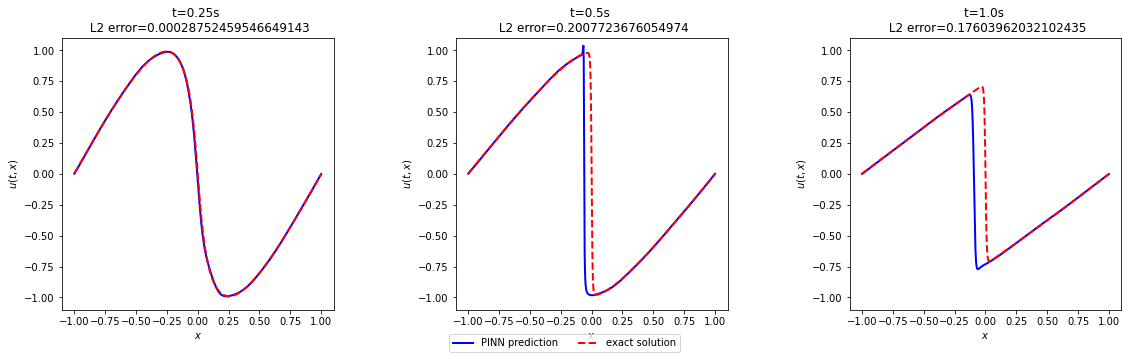

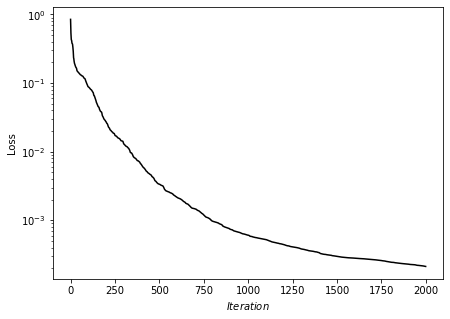

In [46]:
conv_study(N_0=100,N_b=100,N_r=1_000,num_hidden_layers=5,num_neurons_per_layer=10)

Iteration 00000: loss = 6.07875764e-01
Iteration 00100: loss = 9.40216407e-02
Iteration 00200: loss = 3.28900330e-02
Iteration 00300: loss = 7.68954027e-03
Iteration 00400: loss = 3.04815639e-03
Iteration 00500: loss = 1.40473002e-03
Iteration 00600: loss = 6.26269495e-04
Iteration 00700: loss = 3.16727848e-04
Iteration 00800: loss = 1.80591800e-04
Iteration 00900: loss = 1.33919457e-04
Iteration 01000: loss = 9.11535099e-05
Iteration 01100: loss = 7.04577251e-05
Iteration 01200: loss = 5.42591042e-05
Iteration 01300: loss = 4.48499304e-05
Iteration 01400: loss = 3.66143067e-05
Iteration 01500: loss = 3.07538467e-05
Iteration 01600: loss = 2.55793220e-05
Iteration 01700: loss = 2.24324158e-05
Iteration 01800: loss = 2.07090707e-05
Iteration 01900: loss = 1.90293322e-05

Training time: 159.48925375938416 seconds


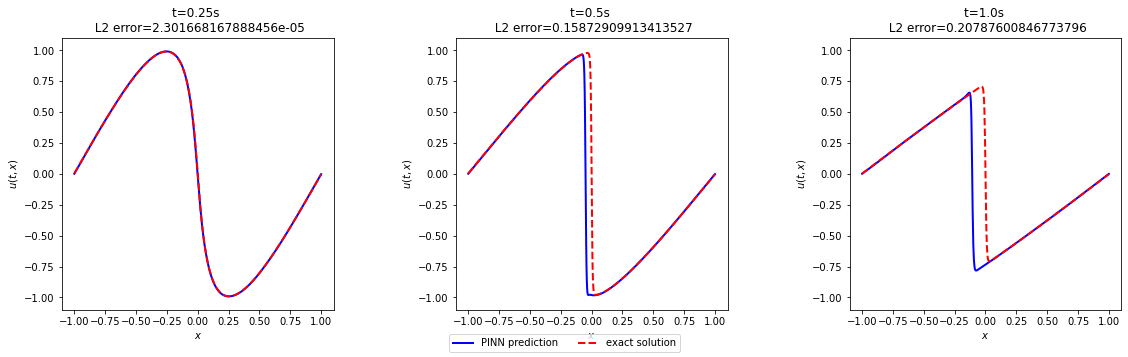

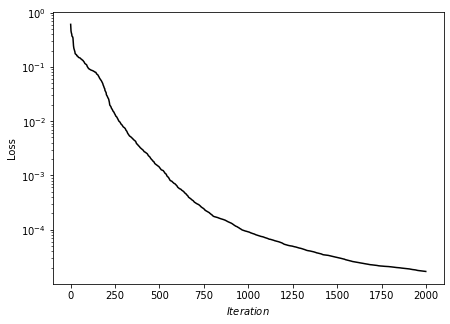

In [47]:
conv_study(N_0=100,N_b=100,N_r=1_000,num_hidden_layers=8,num_neurons_per_layer=20)

Iteration 00000: loss = 5.44968784e-01
Iteration 00100: loss = 1.09458819e-01
Iteration 00200: loss = 6.66980445e-02
Iteration 00300: loss = 3.39392386e-02
Iteration 00400: loss = 2.47619841e-02
Iteration 00500: loss = 1.59468576e-02
Iteration 00600: loss = 9.59286001e-03
Iteration 00700: loss = 7.84640852e-03
Iteration 00800: loss = 5.75568480e-03
Iteration 00900: loss = 5.01914043e-03
Iteration 01000: loss = 4.48311958e-03
Iteration 01100: loss = 3.70553834e-03
Iteration 01200: loss = 3.14629381e-03
Iteration 01300: loss = 2.79867486e-03
Iteration 01400: loss = 2.31504184e-03
Iteration 01500: loss = 1.87336130e-03
Iteration 01600: loss = 1.49869476e-03
Iteration 01700: loss = 1.29029807e-03
Iteration 01800: loss = 1.17589615e-03
Iteration 01900: loss = 9.26161942e-04

Training time: 439.15285992622375 seconds


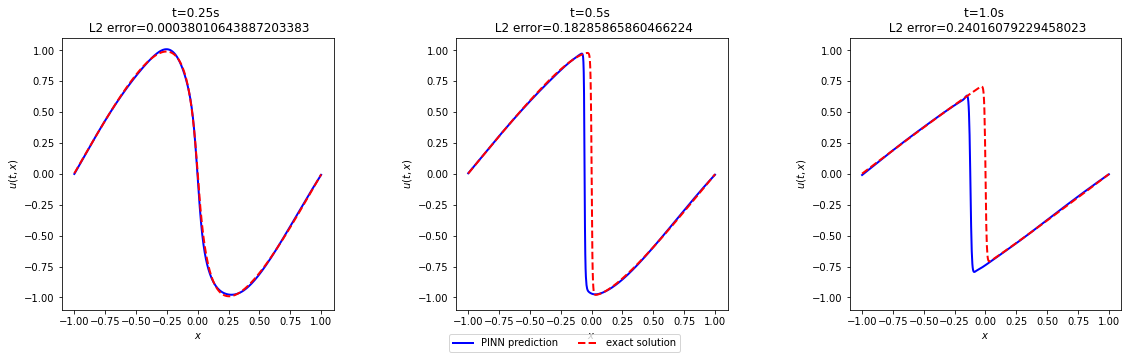

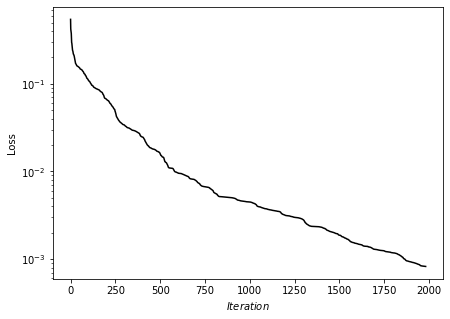

In [48]:
conv_study(N_0=100,N_b=100,N_r=1_000,num_hidden_layers=20,num_neurons_per_layer=50)

## Influence des données d'entrainements

Modèle avec 8 couches de 20 neuronnes chacune 

Iteration 00000: loss = 6.06308222e-01
Iteration 00100: loss = 4.84424233e-02
Iteration 00200: loss = 1.68625489e-02
Iteration 00300: loss = 1.41372606e-02
Iteration 00400: loss = 1.23574072e-02
Iteration 00500: loss = 1.14972005e-02
Iteration 00600: loss = 1.04974136e-02
Iteration 00700: loss = 9.58632212e-03
Iteration 00800: loss = 9.23205633e-03
Iteration 00900: loss = 8.76472238e-03
Iteration 01000: loss = 8.61058012e-03

Training time: 89.73061013221741 seconds


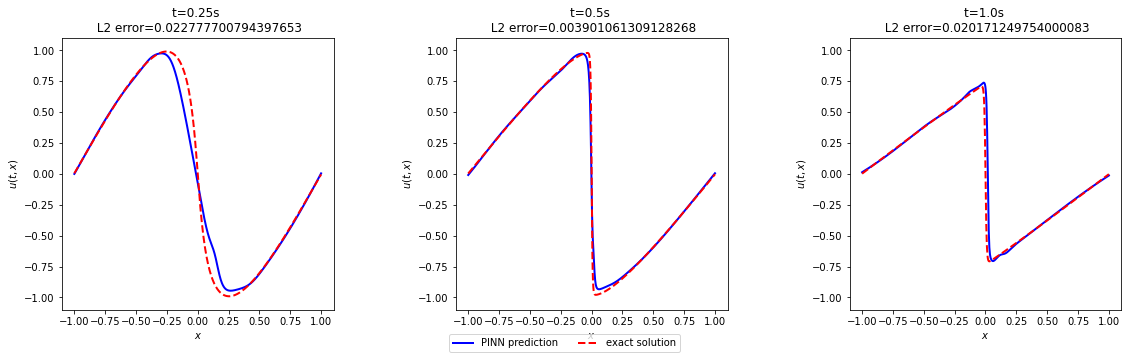

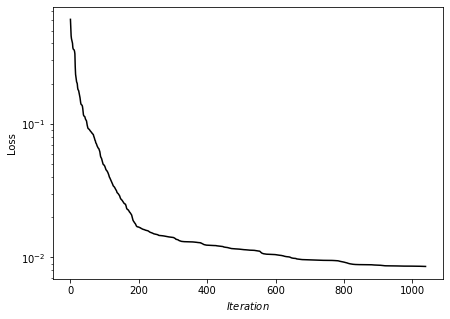

In [49]:
conv_study(N_0=100,N_b=100,N_r=1_000,num_hidden_layers=8,num_neurons_per_layer=20)

Iteration 00000: loss = 6.05527699e-01
Iteration 00100: loss = 1.06560543e-01
Iteration 00200: loss = 4.01331633e-02
Iteration 00300: loss = 9.85801034e-03
Iteration 00400: loss = 4.29452443e-03
Iteration 00500: loss = 1.96634629e-03
Iteration 00600: loss = 1.27074751e-03
Iteration 00700: loss = 8.08557787e-04
Iteration 00800: loss = 5.74878475e-04
Iteration 00900: loss = 3.93833005e-04
Iteration 01000: loss = 2.88344774e-04
Iteration 01100: loss = 2.30387159e-04
Iteration 01200: loss = 1.82619173e-04
Iteration 01300: loss = 1.53460976e-04
Iteration 01400: loss = 1.29507811e-04
Iteration 01500: loss = 1.04257138e-04
Iteration 01600: loss = 8.71040320e-05
Iteration 01700: loss = 7.31602704e-05
Iteration 01800: loss = 6.17936821e-05
Iteration 01900: loss = 5.41517220e-05

Training time: 165.22303295135498 seconds


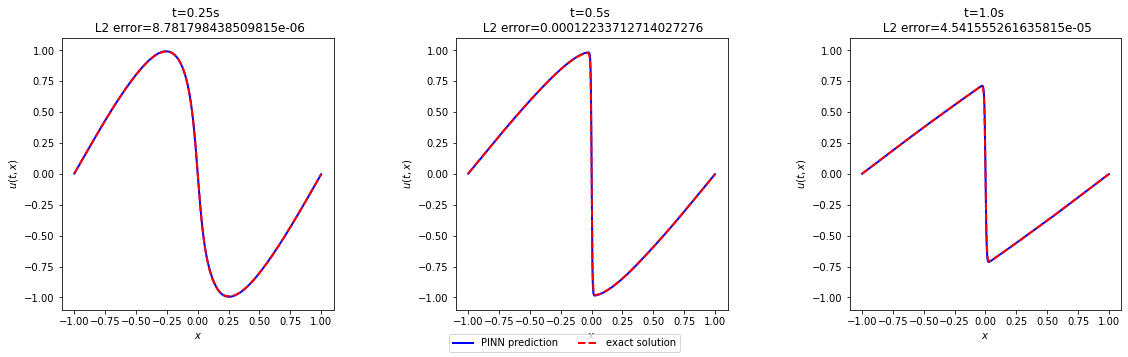

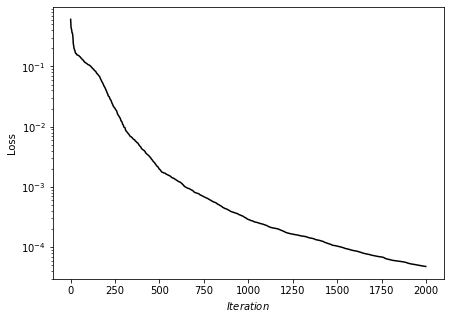

In [50]:
conv_study(N_0=1_000,N_b=1_000,N_r=10_000,num_hidden_layers=8,num_neurons_per_layer=20)

Iteration 00000: loss = 6.08343720e-01
Iteration 00100: loss = 8.30246210e-02
Iteration 00200: loss = 2.08978597e-02
Iteration 00300: loss = 5.66326454e-03
Iteration 00400: loss = 2.22397852e-03
Iteration 00500: loss = 1.28466636e-03
Iteration 00600: loss = 6.77757431e-04
Iteration 00700: loss = 4.75520239e-04
Iteration 00800: loss = 3.52357514e-04
Iteration 00900: loss = 2.68044998e-04
Iteration 01000: loss = 2.07014222e-04
Iteration 01100: loss = 1.71156600e-04
Iteration 01200: loss = 1.42967678e-04
Iteration 01300: loss = 1.17470496e-04
Iteration 01400: loss = 9.45931897e-05
Iteration 01500: loss = 8.01799833e-05
Iteration 01600: loss = 6.90422094e-05
Iteration 01700: loss = 5.97652397e-05
Iteration 01800: loss = 5.30231337e-05
Iteration 01900: loss = 4.79702758e-05

Training time: 163.7327220439911 seconds


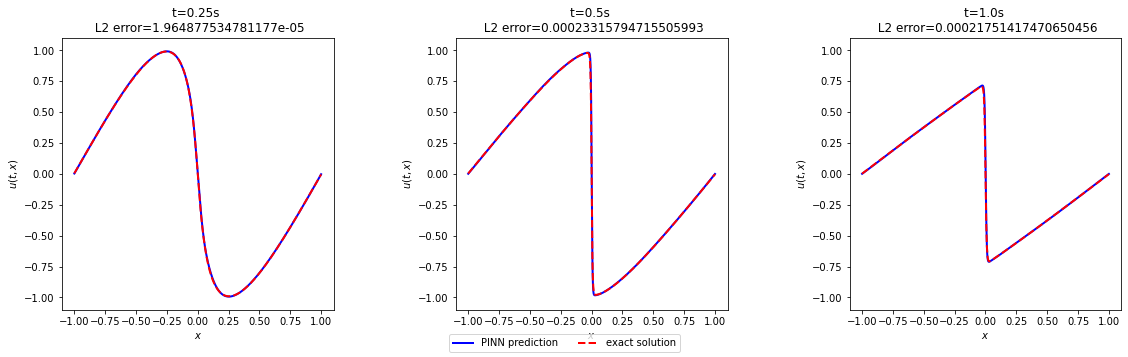

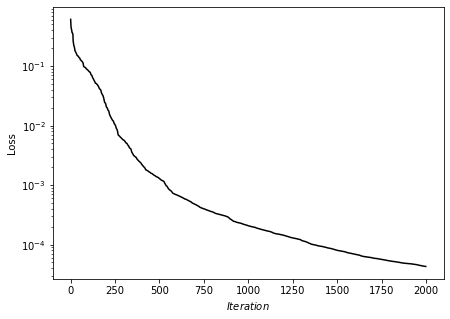

In [51]:
conv_study(N_0=100,N_b=100,N_r=10_000,num_hidden_layers=8,num_neurons_per_layer=20)

Iteration 00000: loss = 6.08132362e-01
Iteration 00100: loss = 8.64601210e-02
Iteration 00200: loss = 2.70805005e-02
Iteration 00300: loss = 1.72301959e-02
Iteration 00400: loss = 1.18314400e-02
Iteration 00500: loss = 6.17829105e-03
Iteration 00600: loss = 4.24622372e-03
Iteration 00700: loss = 3.45947500e-03
Iteration 00800: loss = 3.07169184e-03
Iteration 00900: loss = 2.89579318e-03
Iteration 01000: loss = 2.72125122e-03
Iteration 01100: loss = 2.57910648e-03
Iteration 01200: loss = 2.46999506e-03
Iteration 01300: loss = 2.36589415e-03
Iteration 01400: loss = 2.26796279e-03
Iteration 01500: loss = 2.07454292e-03
Iteration 01600: loss = 1.79627188e-03
Iteration 01700: loss = 1.46453013e-03
Iteration 01800: loss = 1.17964973e-03
Iteration 01900: loss = 8.50597571e-04

Training time: 162.97506427764893 seconds


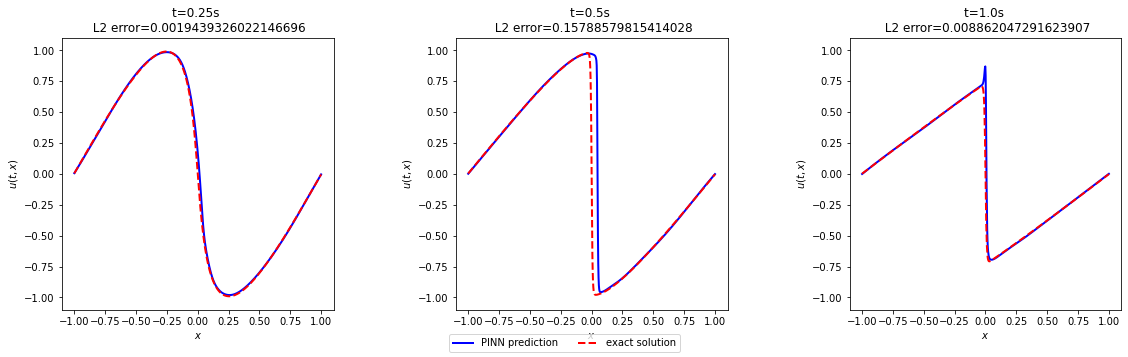

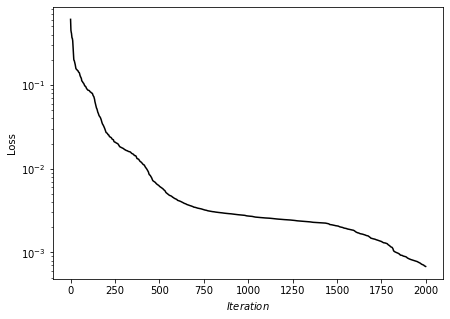

In [52]:
conv_study(N_0=1_000,N_b=100,N_r=1_000,num_hidden_layers=8,num_neurons_per_layer=20)

## D'autres valeurs pour la viscosité

In [53]:
np.logspace(-4,-2,10)

array([0.0001    , 0.00016681, 0.00027826, 0.00046416, 0.00077426,
       0.00129155, 0.00215443, 0.00359381, 0.00599484, 0.01      ])


Viscosity=0.0001
Iteration 00000: loss = 6.04400039e-01
Iteration 00100: loss = 1.16357848e-01
Iteration 00200: loss = 9.12488922e-02
Iteration 00300: loss = 7.79903829e-02
Iteration 00400: loss = 7.59392679e-02
Iteration 00500: loss = 7.48641789e-02
Iteration 00600: loss = 7.40121976e-02
Iteration 00700: loss = 7.34066144e-02
Iteration 00800: loss = 7.31393397e-02
Iteration 00900: loss = 7.28543252e-02
Iteration 01000: loss = 7.26381838e-02
Iteration 01100: loss = 7.23389685e-02

Training time: 101.62381601333618 seconds

Viscosity=0.0001668100537200059
Iteration 00000: loss = 6.05628371e-01
Iteration 00100: loss = 1.19411394e-01
Iteration 00200: loss = 9.36572775e-02
Iteration 00300: loss = 7.92730302e-02
Iteration 00400: loss = 7.42571130e-02
Iteration 00500: loss = 7.27491453e-02
Iteration 00600: loss = 7.23122731e-02
Iteration 00700: loss = 7.18901977e-02
Iteration 00800: loss = 7.17089102e-02
Iteration 00900: loss = 7.15574175e-02
Iteration 01000: loss = 7.13593811e-02
Iteration

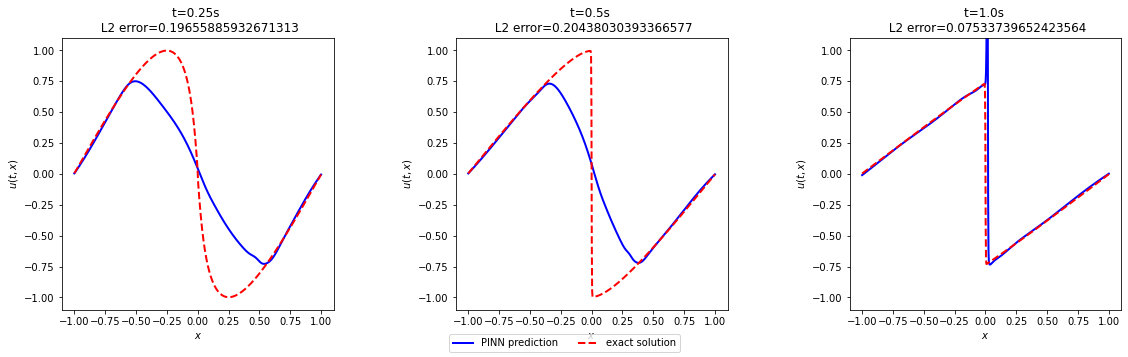

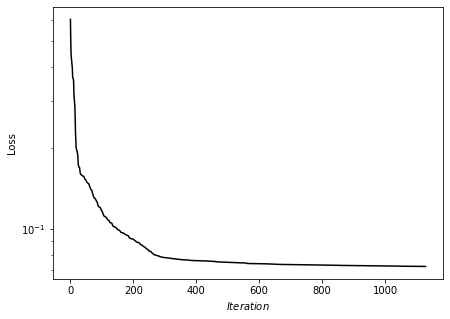

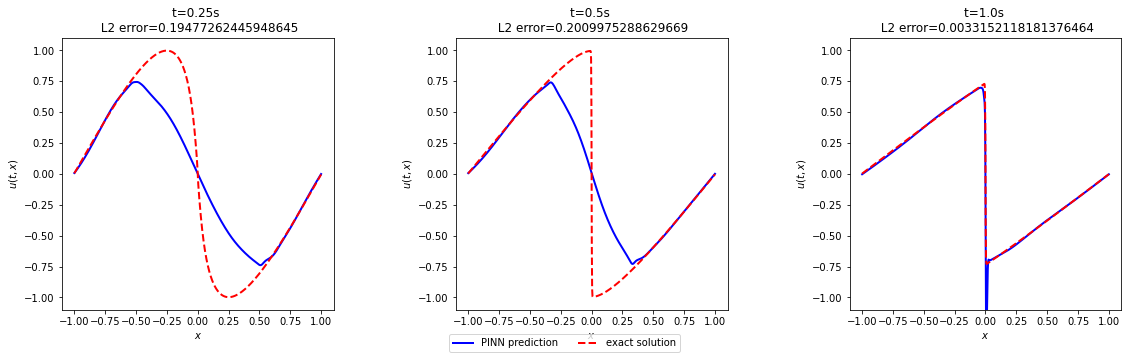

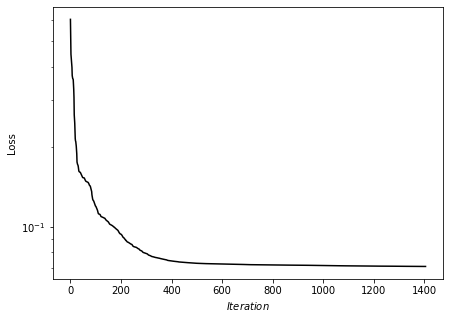

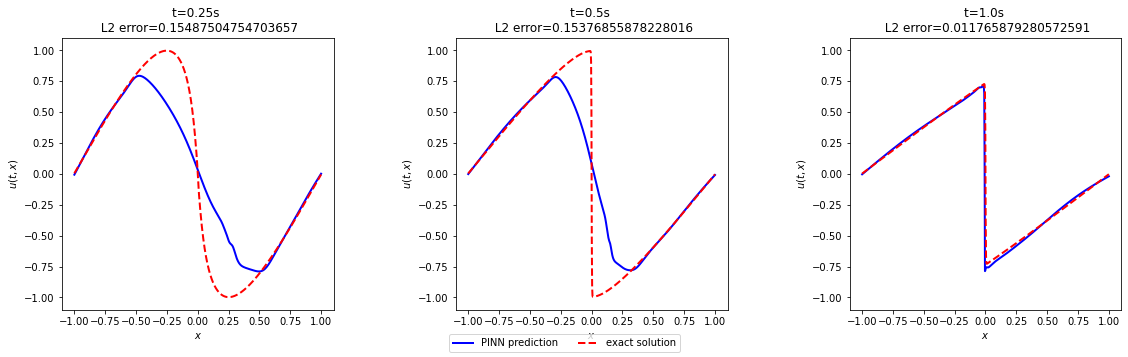

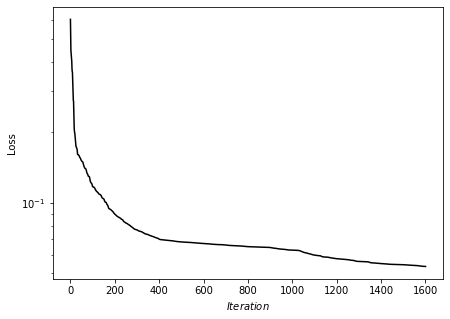

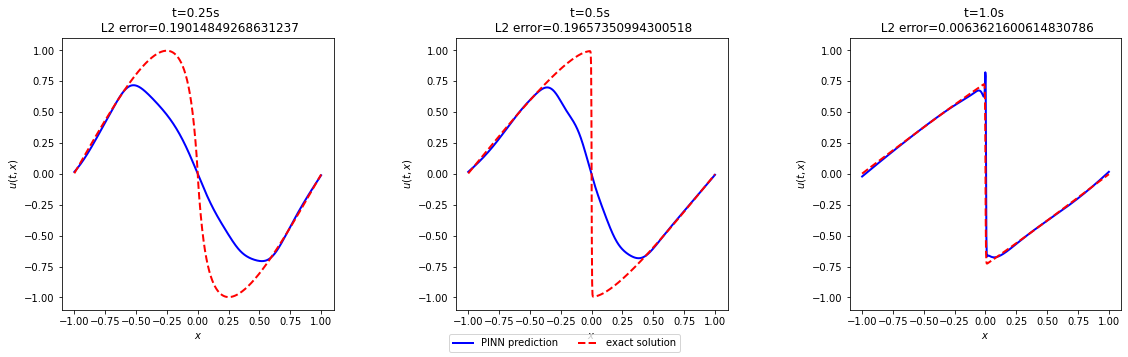

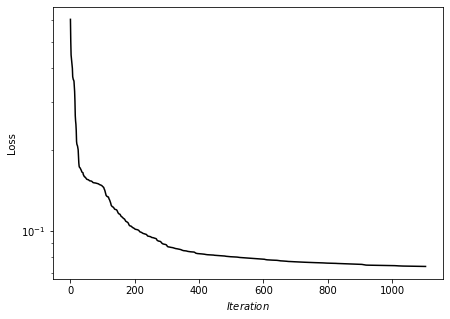

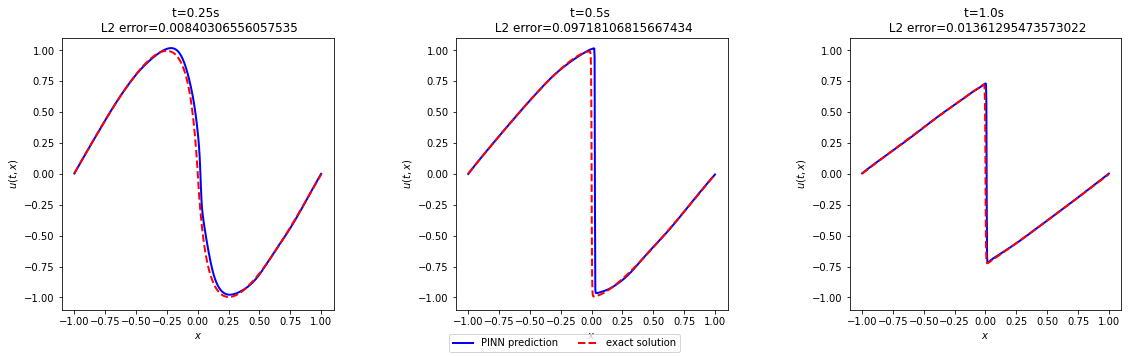

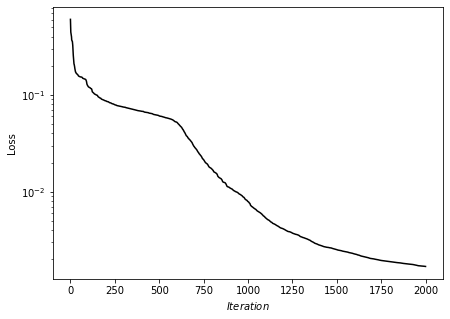

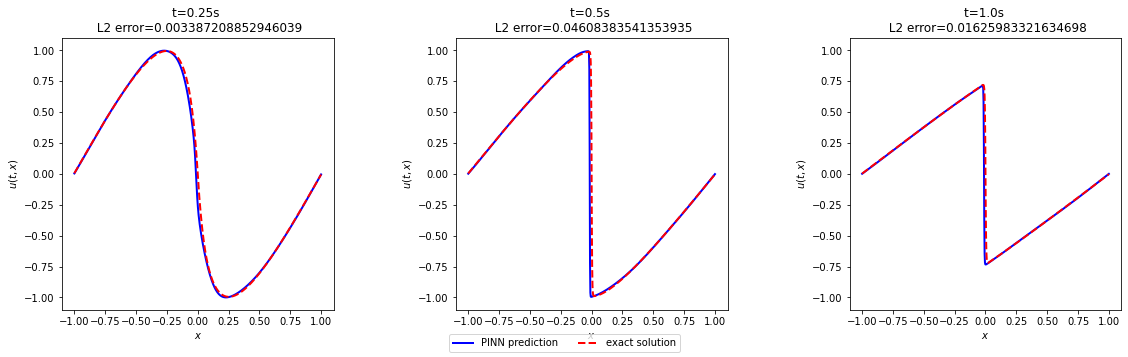

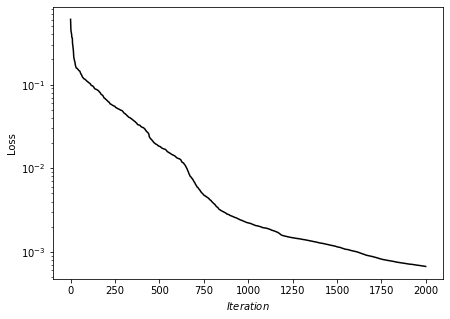

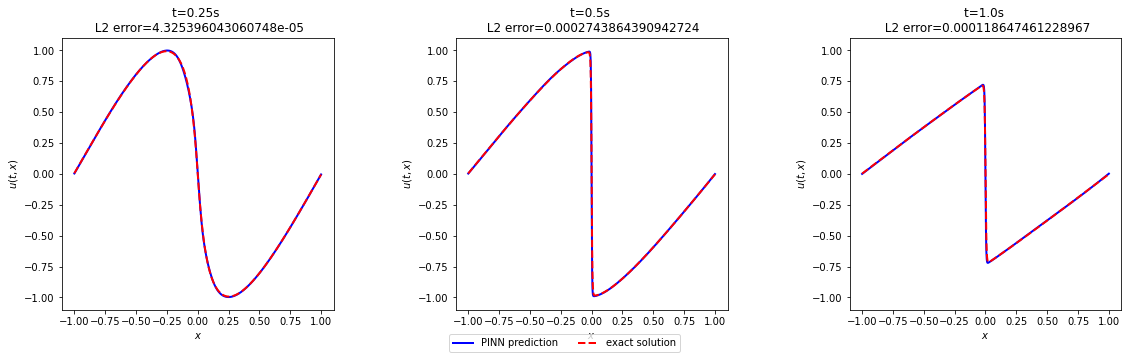

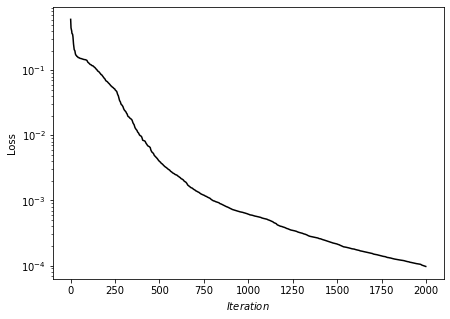

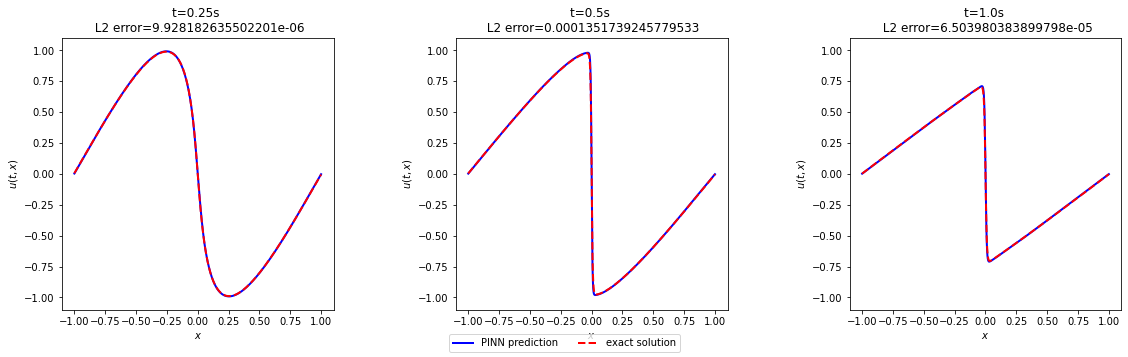

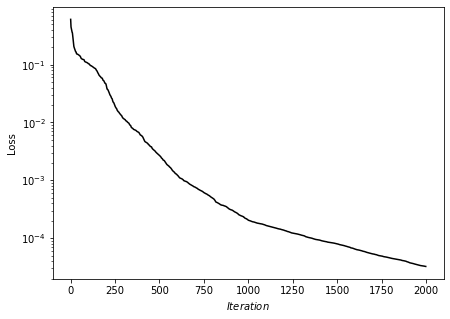

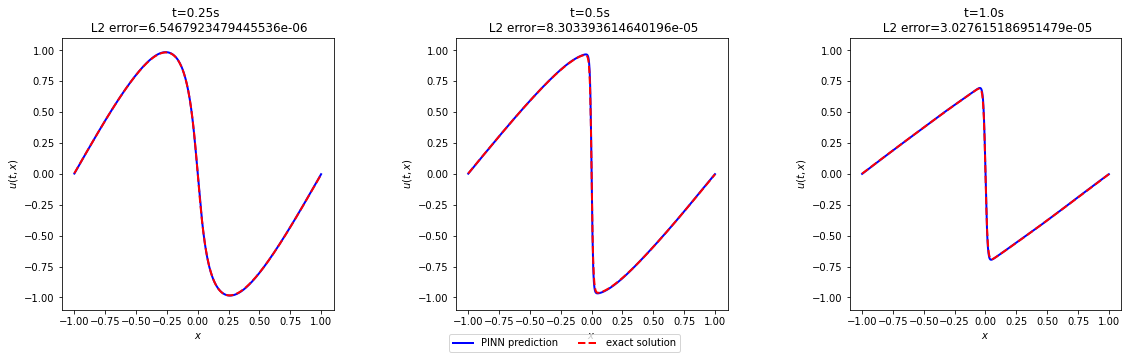

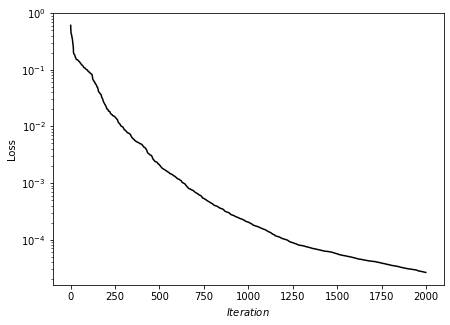

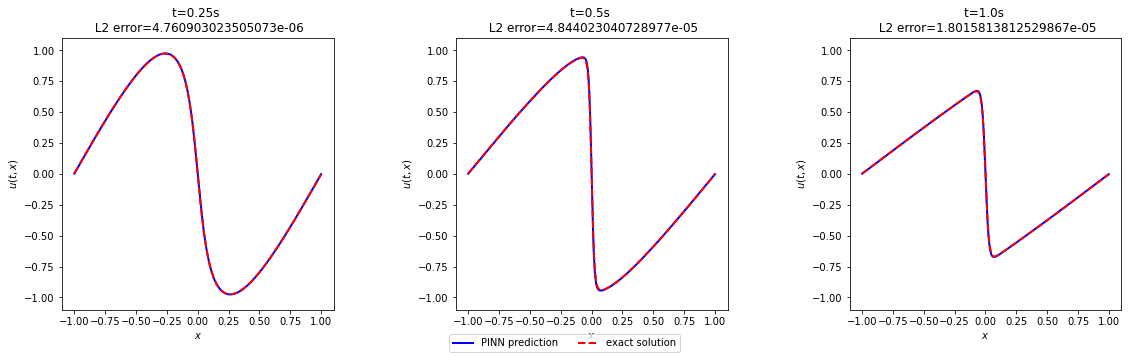

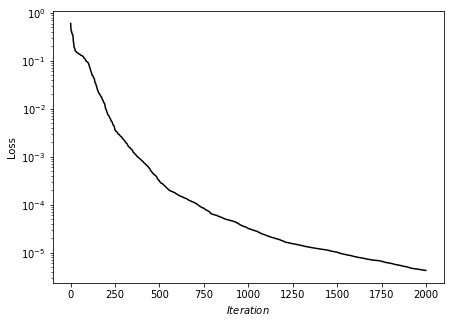

In [54]:
for viscosity in np.logspace(-4,-2,10):

  print("\nViscosity={}".format(viscosity))

  # calcul la solution exacte 
  all_times = [0.25, 0.5, 1.0]
  exact_solutions = []
  N = 700

  bg=EDP(N, viscosity , u_0)
  x = bg.cells[bg.begin:bg.end]

  for i_t, end_time in enumerate(all_times):
    bg.init()
    sol=bg.solve(end_time)
    exact_solutions.append(sol[-1])

  # PINN
  conv_study(N_0=1000,N_b=1000,N_r=10000,num_hidden_layers=8,num_neurons_per_layer=20)